?? Omitiendo corner por error de convergencia: V_1_62_T_-40_lh
?? Omitiendo corner por error de convergencia: V_1_62_T_-40_fs_ll
?? Omitiendo corner por error de convergencia: V_1_8_T_27_sf_ll


/tmp/ipykernel_852/1399579582.py:51: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


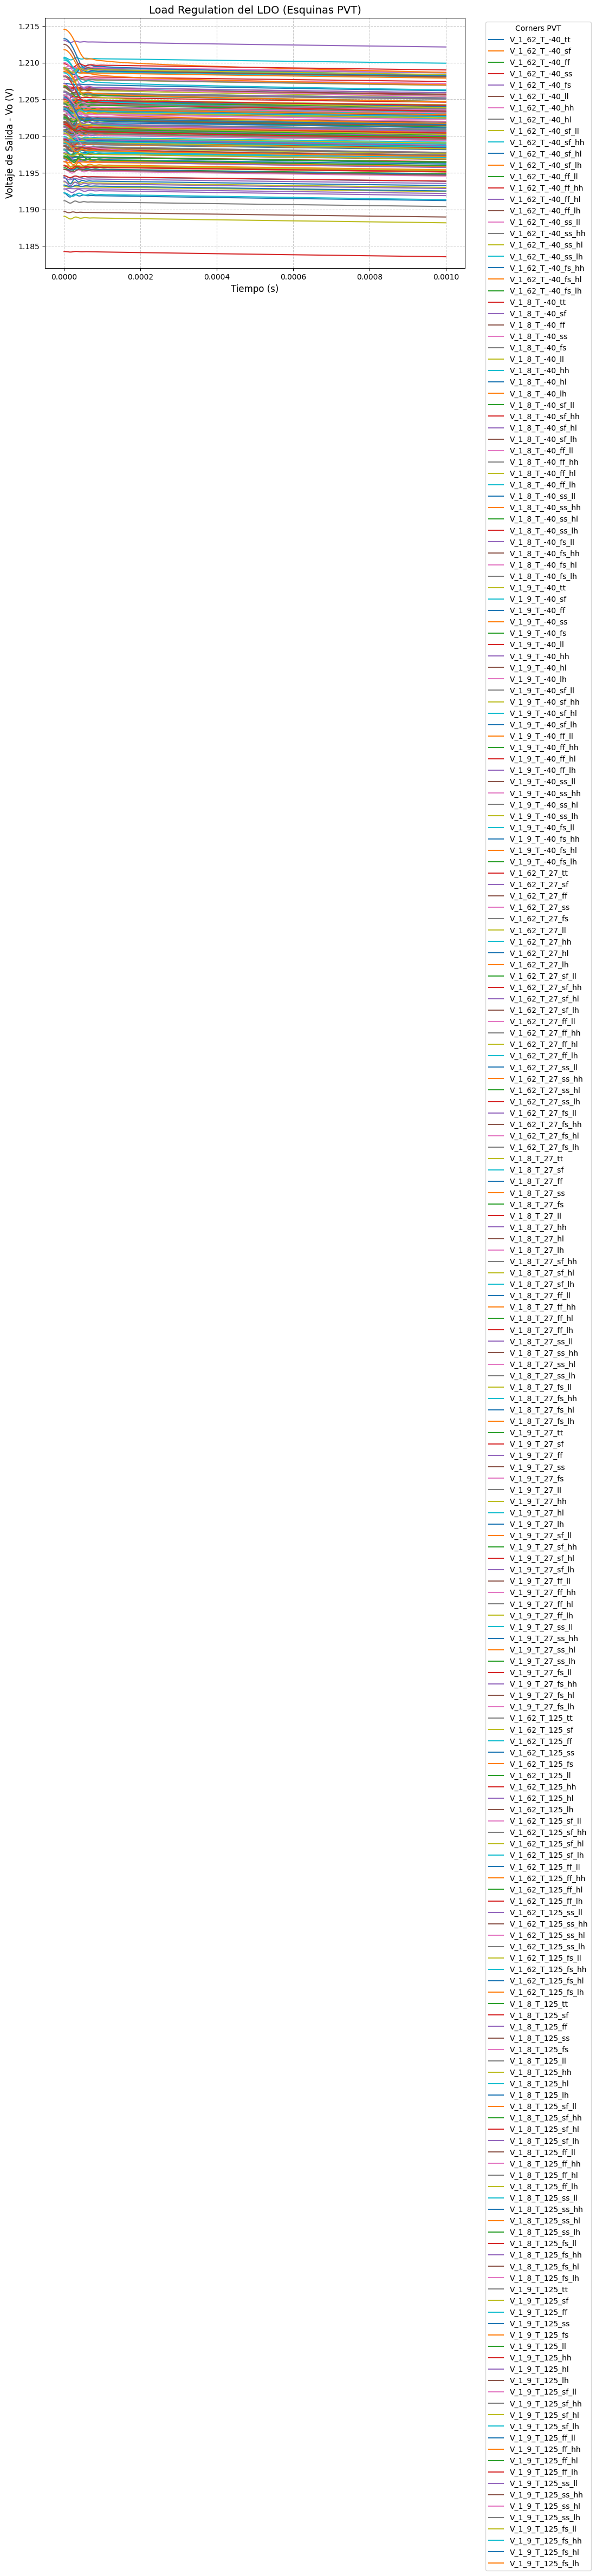

In [1]:
import pickle
import matplotlib.pyplot as plt

# 1. Cargar los datos
carpeta_destino = "resultados_simulacion"

with open(f"{carpeta_destino}/graficas_ldo.pkl", 'rb') as archivo:
    graficas_cargadas = pickle.load(archivo)

# 2. Lista de corners con problemas de convergencia (escribe aquí los nombres exactos)
corners_ignorados = [
    "V_1_62_T_-40_lh",
    "V_1_62_T_-40_fs_ll",
    "V_1_8_T_27_sf_ll",
    
    # Agrega más llaves aquí según necesites, separados por comas
]

# 3. Configurar la gráfica
plt.figure(figsize=(10, 6))
graficas_dibujadas = 0

# Iterar sobre todos los corners guardados
for llave_pvt, datos_grafica in graficas_cargadas.items():
    
    # Si la llave está en tu lista negra, saltarla
    if llave_pvt in corners_ignorados:
        print(f"?? Omitiendo corner por error de convergencia: {llave_pvt}")
        continue
        
    # Verificar que los datos de load regulation existan en este corner
    if "load_time" in datos_grafica and "load_vo" in datos_grafica:
        tiempo = datos_grafica["load_time"]
        voltaje_out = datos_grafica["load_vo"]
        
        # Graficar
        plt.plot(tiempo, voltaje_out, label=llave_pvt)
        graficas_dibujadas += 1

# 4. Detalles visuales de la gráfica
if graficas_dibujadas > 0:
    plt.title("Load Regulation del LDO (Esquinas PVT)", fontsize=14)
    plt.xlabel("Tiempo (s)", fontsize=12)
    plt.ylabel("Voltaje de Salida - Vo (V)", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # Mover la leyenda afuera a la derecha para que no tape las formas de onda
    plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left", title="Corners PVT")
    
    # Ajustar el diseño para que la leyenda no se corte al guardar/mostrar
    plt.tight_layout() 
    plt.show()
else:
    print("? No se dibujó ninguna gráfica. Verifica que los nombres de las variables sean correctos o que no hayas ignorado todas las llaves.")